
# مباحث ویژه 1 - تکلیف 1: پیش‌بینی ریزش مشتریان با یادگیری گروهی
# توسعه‌دهنده: پروژه پیش‌بینی ریزش مشتریان
# تاریخ گزارش: ۱۷ آبان ۱۴۰۵

 ## تعریف مسئله و هدف کسب‌وکار
# هدف این پروژه ساخت یک سیستم هوشمند برای امتیازدهی به مشتریان بر اساس ریسک ریزش (Churn) است.
# در این گزارش، عملکرد مدل‌های پایه (خطوط پایه) را با رویکردهای یادگیری گروهی (Ensemble) مقایسه می‌کنیم
# تا مشخص شود آیا ترکیب مدل‌ها عملکرد بهتری ارائه می‌دهد یا خیر.

In [310]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve
)

from sklearn.inspection import permutation_importance

OUTPUT_DIR = "churn_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Libraries imported successfully!")

Libraries imported successfully!


In [311]:
df = pd.read_csv('client_state.csv')
df

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes


In [312]:
print(df.shape)

(7043, 21)


In [313]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

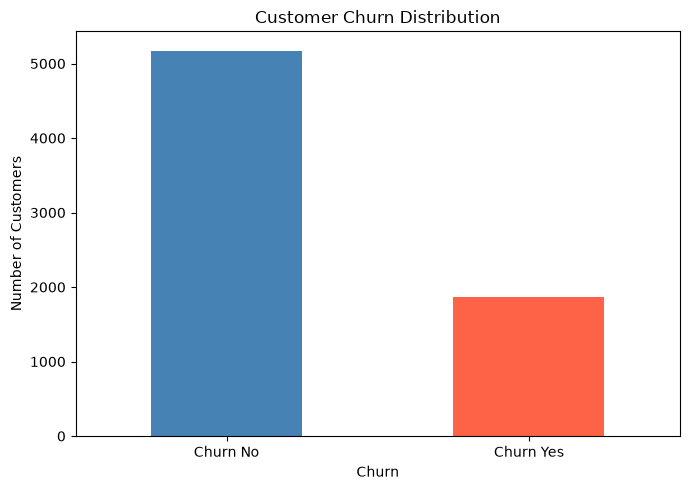

In [314]:
plt.figure(figsize=(7,5))

df["Churn"].value_counts().sort_index().plot(
    kind="bar",
    color=["steelblue", "tomato"]
)

plt.xticks(
    [0,1],
    ["Churn No", "Churn Yes"],
    rotation=0
)

plt.title("Customer Churn Distribution")
plt.ylabel("Number of Customers")
plt.xlabel("Churn")
plt.tight_layout()
plt.show()

In [315]:
cols = df.columns
for col in cols:
    print(f"{col} : {df[col].unique()}")

customerID : <StringArray>
['7590-VHVEG', '5575-GNVDE', '3668-QPYBK', '7795-CFOCW', '9237-HQITU',
 '9305-CDSKC', '1452-KIOVK', '6713-OKOMC', '7892-POOKP', '6388-TABGU',
 ...
 '9767-FFLEM', '0639-TSIQW', '8456-QDAVC', '7750-EYXWZ', '2569-WGERO',
 '6840-RESVB', '2234-XADUH', '4801-JZAZL', '8361-LTMKD', '3186-AJIEK']
Length: 7043, dtype: str
gender : <StringArray>
['Female', 'Male']
Length: 2, dtype: str
SeniorCitizen : [0 1]
Partner : <StringArray>
['Yes', 'No']
Length: 2, dtype: str
Dependents : <StringArray>
['No', 'Yes']
Length: 2, dtype: str
tenure : [ 1 34  2 45  8 22 10 28 62 13 16 58 49 25 69 52 71 21 12 30 47 72 17 27
  5 46 11 70 63 43 15 60 18 66  9  3 31 50 64 56  7 42 35 48 29 65 38 68
 32 55 37 36 41  6  4 33 67 23 57 61 14 20 53 40 59 24 44 19 54 51 26  0
 39]
PhoneService : <StringArray>
['No', 'Yes']
Length: 2, dtype: str
MultipleLines : <StringArray>
['No phone service', 'No', 'Yes']
Length: 3, dtype: str
InternetService : <StringArray>
['DSL', 'Fiber optic', 'No']
Lengt

# Different ways to drop columns
## Method 1: Using drop()
### This is the most common and flexible way to remove columns in Pandas.
### Syntax:  df.drop(columns=['column_name'])

You can also use:

In [316]:
df.drop(['customerID'], axis=1, inplace=True)

In [317]:
df = pd.get_dummies(
    df,
    columns=['gender', 'PaymentMethod'],
    dtype=int
)

In [318]:
columns = ['Partner', 'Dependents', 'PhoneService', 'PaperlessBilling', 'Churn']

for col in columns:
    df[col] = df[col].map({
        'Yes': 1,
        'No': 0
    })

In [319]:
df['MultipleLines'] = df['MultipleLines'].map({
    'No phone service': 0,
    'No': -1,
    'Yes':1
})

In [320]:
df['InternetService'] = df['InternetService'].map({
    'No':0,
    'DSL': 1,
    'Fiber optic':2
})

In [321]:
columns = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']

for col in columns:
    df[col] = df[col].map({
    'No':-1,
    'Yes':1,
    'No internet service':0
})

In [322]:
df['Contract'] = df['Contract'].map({
    'Month-to-month':1,
    'One year': 2,
    'Two year':3
})

In [323]:
print(df.groupby('Churn').mean(numeric_only=True))

       SeniorCitizen   Partner  Dependents     tenure  PhoneService  \
Churn                                                                 
0           0.128721  0.528218    0.344801  37.569965      0.901044   
1           0.254682  0.357945    0.174425  17.979133      0.909042   

       MultipleLines  InternetService  OnlineSecurity  OnlineBackup  \
Churn                                                                 
0          -0.081175         1.074604       -0.060495      0.009857   
1           0.000535         1.633494       -0.623863     -0.379882   

       DeviceProtection  ...  StreamingMovies  Contract  PaperlessBilling  \
Churn                    ...                                                
0             -0.001353  ...         0.012949  1.889254          0.535562   
1             -0.356340  ...        -0.064205  1.140182          0.749064   

       MonthlyCharges  gender_Female  gender_Male  \
Churn                                               
0           61.

In [324]:
df

,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,...,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,gender_Female,gender_Male,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,0,1,0,0,1,-1,1,-1,...,1,29.85,29.85,0,1,0,0,0,1,0
1,0,0,0,34,1,-1,1,1,-1,1,...,0,56.95,1889.5,0,0,1,0,0,0,1
2,0,0,0,2,1,-1,1,1,1,-1,...,1,53.85,108.15,1,0,1,0,0,0,1
3,0,0,0,45,0,0,1,1,-1,1,...,0,42.30,1840.75,0,0,1,1,0,0,0
4,0,0,0,2,1,-1,2,-1,-1,-1,...,1,70.70,151.65,1,1,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,0,1,1,24,1,1,1,1,-1,1,...,1,84.80,1990.5,0,0,1,0,0,0,1
7039,0,1,1,72,1,1,2,-1,1,1,...,1,103.20,7362.9,0,1,0,0,1,0,0
7040,0,1,1,11,0,0,1,1,-1,-1,...,1,29.60,346.45,0,1,0,0,0,1,0
7041,1,1,0,4,1,1,2,-1,-1,-1,...,1,74.40,306.6,1,0,1,0,0,0,1


In [325]:
df = df.apply(pd.to_numeric, errors='coerce')

In [326]:
missing_values = df.isnull().sum()
missing_values = missing_values[missing_values > 0].sort_values()
missing_values

TotalCharges    11
dtype: int64

In [327]:
df.fillna(df.mean(), inplace=True)

,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,...,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,gender_Female,gender_Male,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,0,1,0,0,1,-1,1,-1,...,1,29.85,29.85,0,1,0,0,0,1,0
1,0,0,0,34,1,-1,1,1,-1,1,...,0,56.95,1889.50,0,0,1,0,0,0,1
2,0,0,0,2,1,-1,1,1,1,-1,...,1,53.85,108.15,1,0,1,0,0,0,1
3,0,0,0,45,0,0,1,1,-1,1,...,0,42.30,1840.75,0,0,1,1,0,0,0
4,0,0,0,2,1,-1,2,-1,-1,-1,...,1,70.70,151.65,1,1,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,0,1,1,24,1,1,1,1,-1,1,...,1,84.80,1990.50,0,0,1,0,0,0,1
7039,0,1,1,72,1,1,2,-1,1,1,...,1,103.20,7362.90,0,1,0,0,1,0,0
7040,0,1,1,11,0,0,1,1,-1,-1,...,1,29.60,346.45,0,1,0,0,0,1,0
7041,1,1,0,4,1,1,2,-1,-1,-1,...,1,74.40,306.60,1,0,1,0,0,0,1


<Figure size 700x500 with 0 Axes>

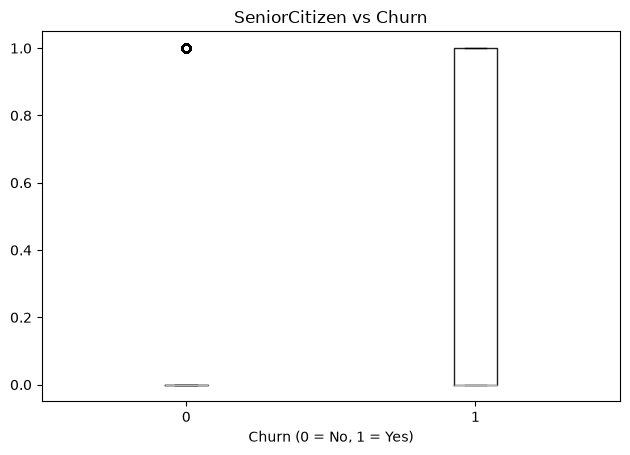

<Figure size 700x500 with 0 Axes>

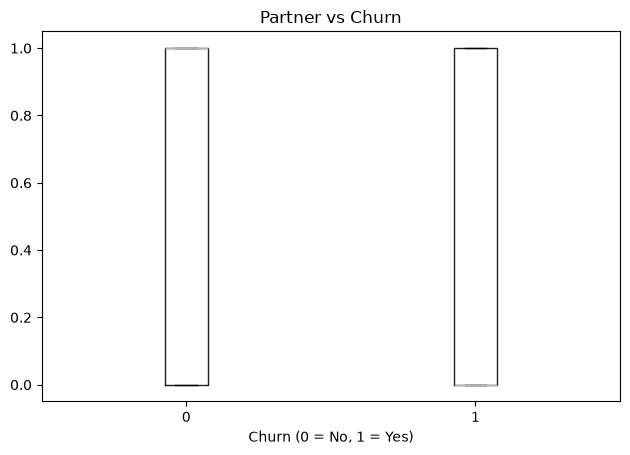

<Figure size 700x500 with 0 Axes>

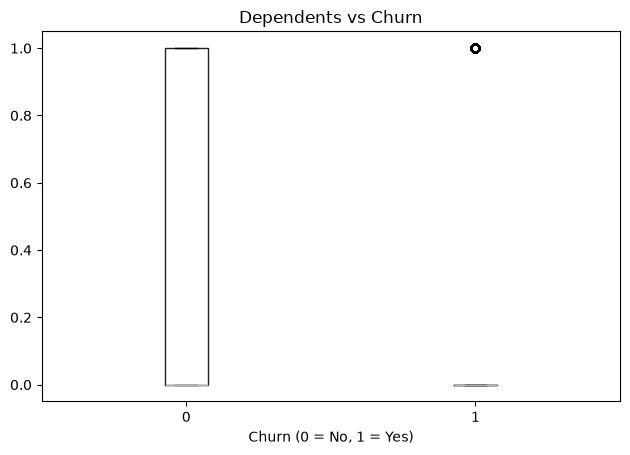

<Figure size 700x500 with 0 Axes>

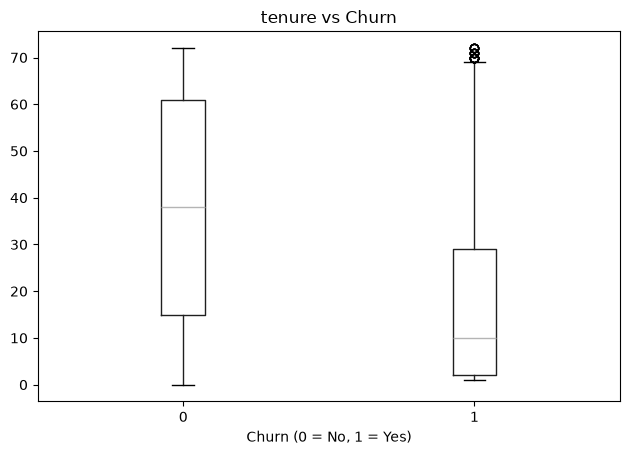

<Figure size 700x500 with 0 Axes>

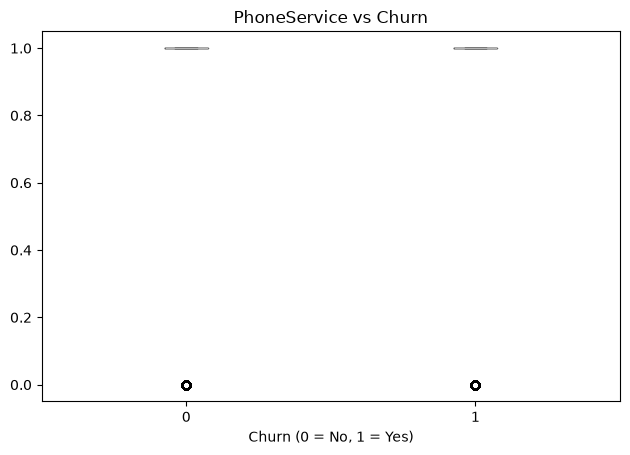

<Figure size 700x500 with 0 Axes>

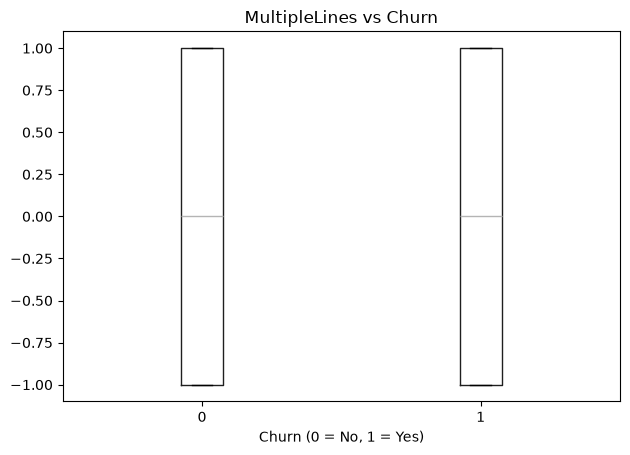

<Figure size 700x500 with 0 Axes>

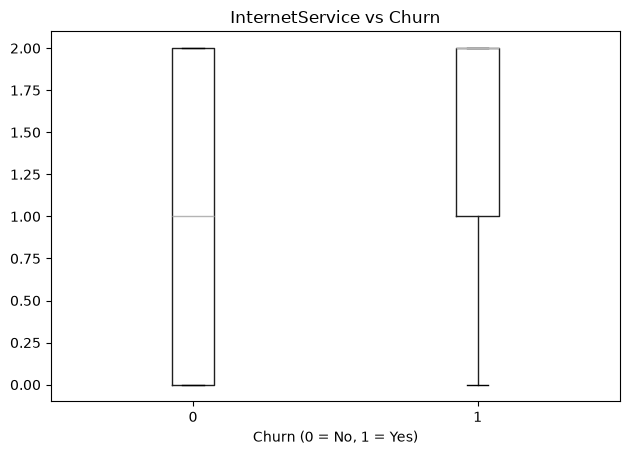

<Figure size 700x500 with 0 Axes>

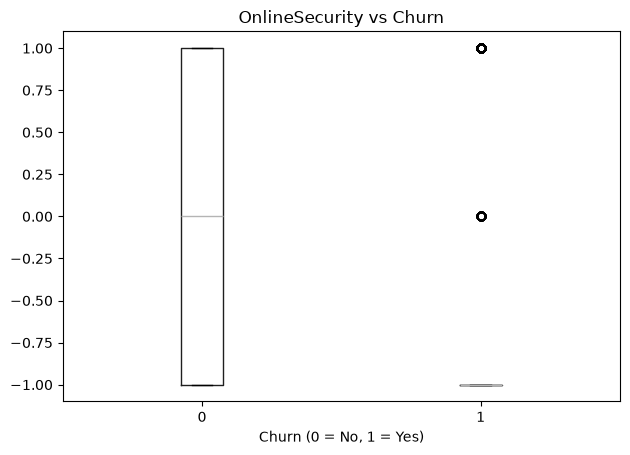

<Figure size 700x500 with 0 Axes>

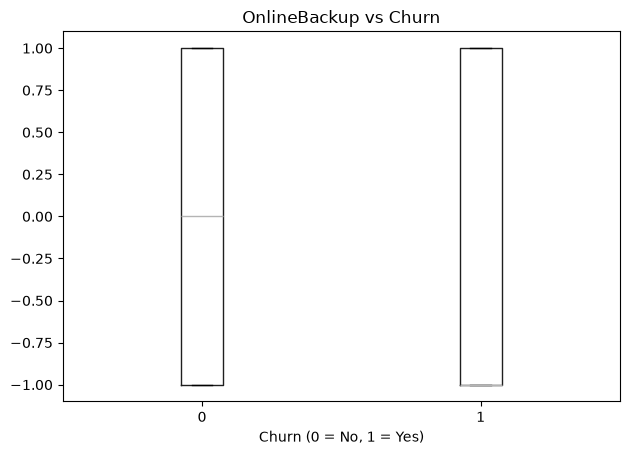

<Figure size 700x500 with 0 Axes>

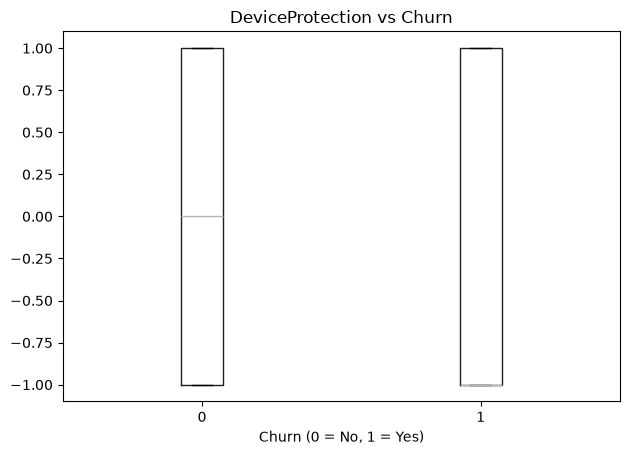

<Figure size 700x500 with 0 Axes>

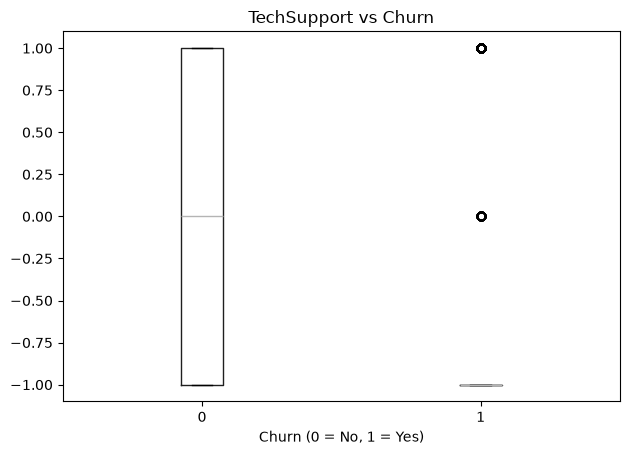

<Figure size 700x500 with 0 Axes>

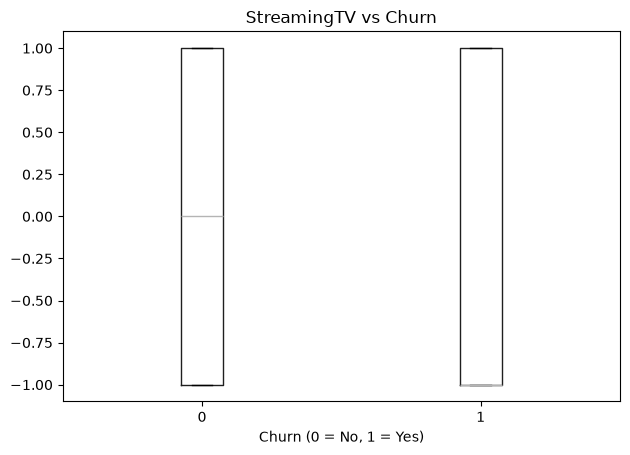

<Figure size 700x500 with 0 Axes>

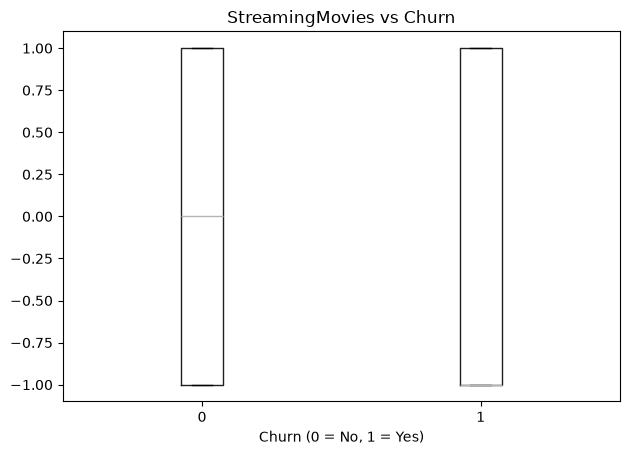

<Figure size 700x500 with 0 Axes>

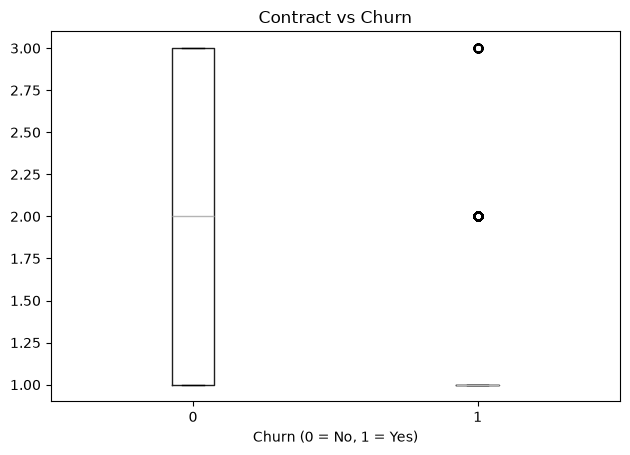

<Figure size 700x500 with 0 Axes>

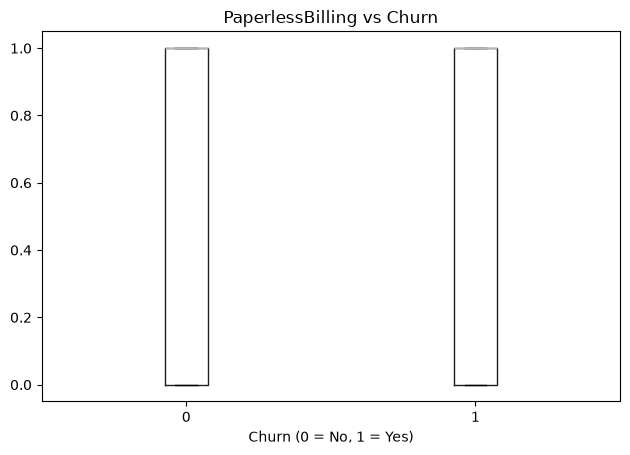

<Figure size 700x500 with 0 Axes>

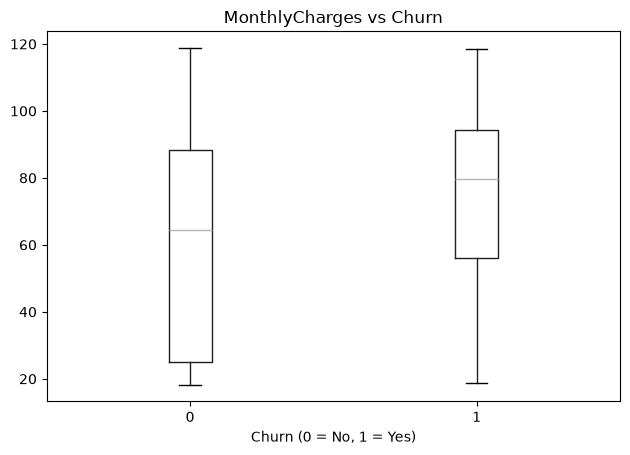

<Figure size 700x500 with 0 Axes>

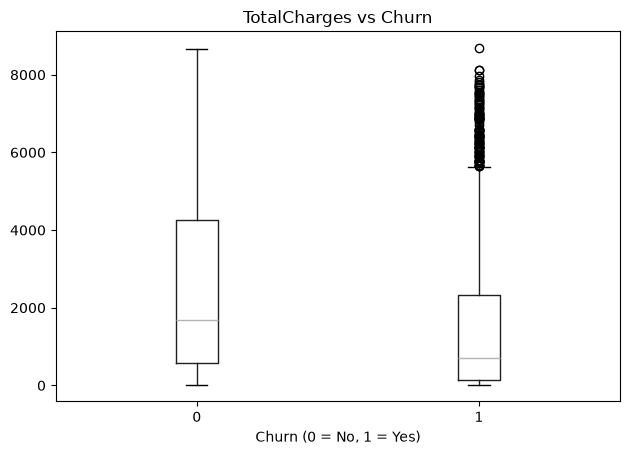

<Figure size 700x500 with 0 Axes>

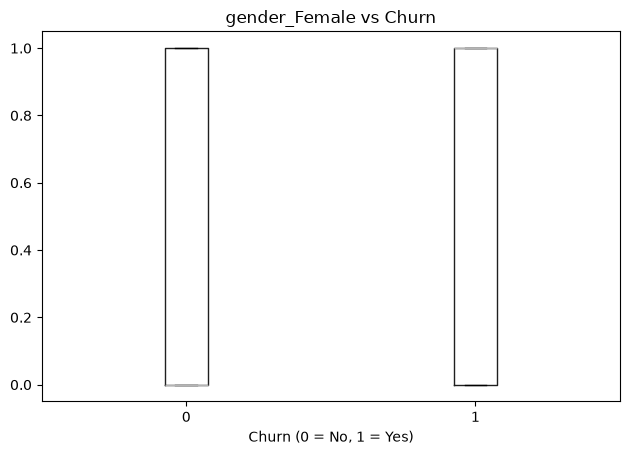

<Figure size 700x500 with 0 Axes>

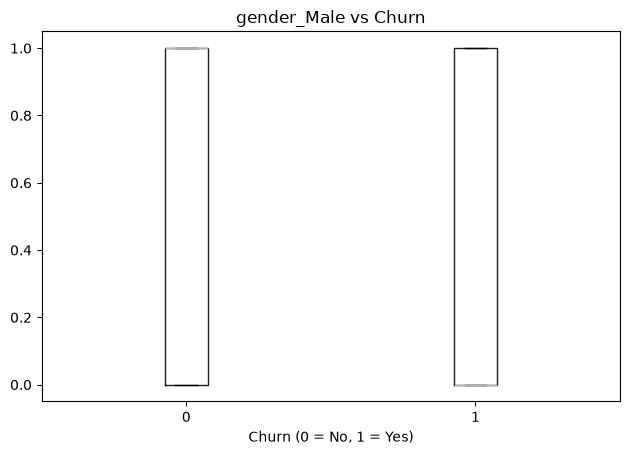

<Figure size 700x500 with 0 Axes>

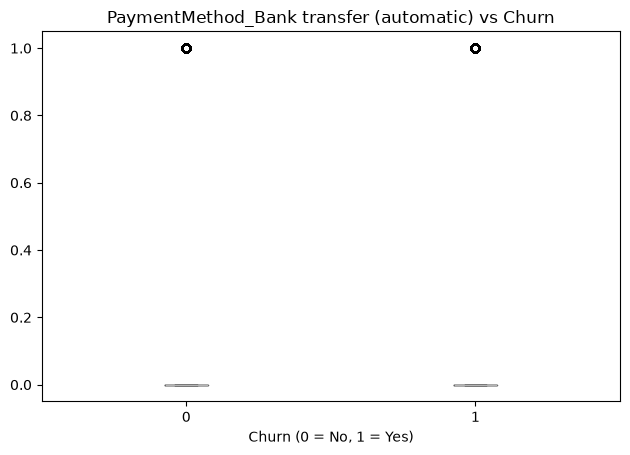

<Figure size 700x500 with 0 Axes>

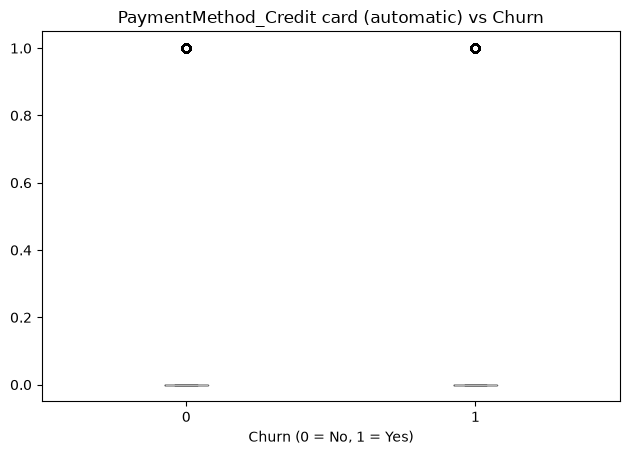

<Figure size 700x500 with 0 Axes>

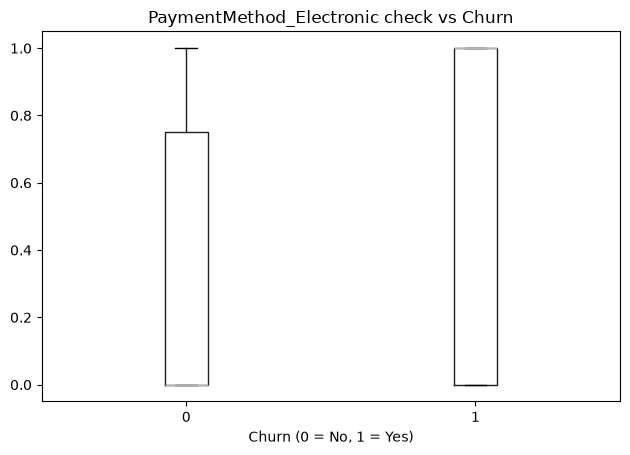

<Figure size 700x500 with 0 Axes>

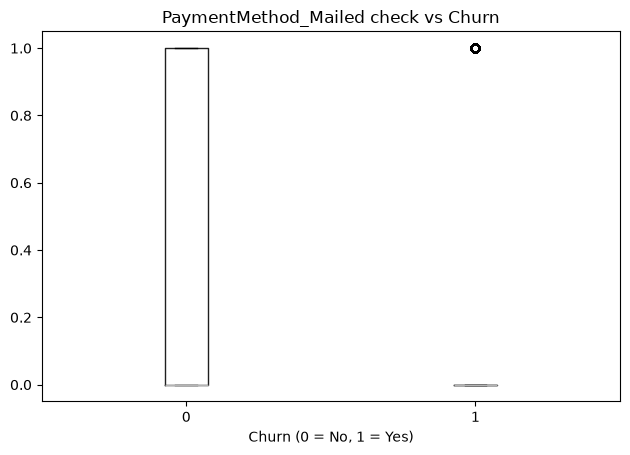

In [328]:
numeric_features = df.select_dtypes(
    include=["number"]
).columns.tolist()

numeric_features.remove("Churn")

for col in numeric_features:

    plt.figure(figsize=(7,5))

    df.boxplot(
        column=col,
        by="Churn",
        grid=False
    )

    plt.title(f"{col} vs Churn")
    plt.suptitle("")
    plt.xlabel("Churn (0 = No, 1 = Yes)")
    plt.tight_layout()
    plt.show()

In [329]:
X = df.drop(['Churn'], axis=1)
y = df['Churn']

In [330]:
scaler = StandardScaler()
cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
X[cols] = scaler.fit_transform(X[cols])

In [331]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size = 0.2,
    random_state = 42
)

In [332]:
classifiers = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "SVM": SVC(kernel="rbf"),
    "Decision Tree": DecisionTreeClassifier(random_state=42)
}

In [333]:
classification_results = []

for name, model in classifiers.items():

    if name == "Decision Tree":
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

    else:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    classification_results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    })

In [334]:
classification_results_df = pd.DataFrame(classification_results)

classification_results_df

,Model,Accuracy,Precision,Recall,F1
0,Logistic Regression,0.821859,0.687117,0.600536,0.640916
1,KNN,0.780696,0.602564,0.504021,0.548905
2,SVM,0.815472,0.710037,0.512064,0.595016
3,Decision Tree,0.716820,0.465608,0.471850,0.468708


first report

In [335]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression

params = {
    'C': [0.01, 0.1, 1, 10, 100],
    'class_weight': [None, 'balanced'],
    'max_iter': [2000, 3000]
}

grid = GridSearchCV(
    LogisticRegression(random_state=42),
    params,
    cv=5,
    scoring='f1',
    n_jobs=-1
)

grid.fit(X_train, y_train)

print(grid.best_params_)
print(grid.best_score_)

{'C': 100, 'class_weight': 'balanced', 'max_iter': 2000}
0.6229102747663499


In [336]:
best_model = LogisticRegression(
    C=100,
    class_weight='balanced',
    max_iter=2000,
    random_state=42
)

best_model.fit(X_train, y_train)

y_pred = best_model.predict(X_test)

In [337]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.92      0.73      0.81      1036
           1       0.52      0.82      0.64       373

    accuracy                           0.75      1409
   macro avg       0.72      0.77      0.72      1409
weighted avg       0.81      0.75      0.77      1409



In [338]:
from sklearn.metrics import confusion_matrix

print(confusion_matrix(y_test, y_pred))

[[752 284]
 [ 66 307]]


In [339]:
logistic_model = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=42
)

In [340]:
decision_tree_model = DecisionTreeClassifier(
    max_depth=5,
    class_weight="balanced",
    random_state=42
)

In [341]:
random_forest_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

In [342]:
from sklearn.ensemble import GradientBoostingClassifier

gradient_boosting_model = GradientBoostingClassifier(
    n_estimators=200,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.8,
    random_state=42
)

In [344]:
stacking_model = StackingClassifier(
    estimators=[
        ("logistic", LogisticRegression(
            max_iter=2000,
            class_weight="balanced"
        )),
        ("decision_tree", DecisionTreeClassifier(
            max_depth=5,
            class_weight="balanced",
            random_state=42
        )),
        ("random_forest", RandomForestClassifier(
            n_estimators=100,
            max_depth=8,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ],
    final_estimator=LogisticRegression(
        max_iter=2000,
        class_weight="balanced"
    ),
    cv=5,
    stack_method="predict_proba",
    n_jobs=-1
)

In [345]:
stacking_svc_model = StackingClassifier(
    estimators=[
        ("logistic", LogisticRegression(
            max_iter=2000,
            class_weight="balanced"
        )),
        ("svc", SVC(
            probability=True,
            class_weight="balanced",
            random_state=42
        )),
        ("random_forest", RandomForestClassifier(
            n_estimators=100,
            max_depth=8,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ],
    final_estimator=LogisticRegression(
        max_iter=2000,
        class_weight="balanced"
    ),
    cv=5,
    stack_method="predict_proba",
    n_jobs=-1
)

In [346]:
models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": decision_tree_model,
    "Random Forest": random_forest_model,
    "XGBoost": gradient_boosting_model,
    "Stacking": stacking_model,
    "Stacking with SVC": stacking_svc_model
}

results = []
predictions = {}
probabilities = {}

for name, model in models.items():

    print("\nTraining:", name)

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    y_prob = model.predict_proba(X_test)[:, 1]

    predictions[name] = y_pred
    probabilities[name] = y_prob

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

    print(classification_report(y_test, y_pred))

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        by="F1",
        ascending=False
    )
)

results_df.to_csv(
    f"{OUTPUT_DIR}/model_comparison.csv",
    index=False
)


Training: Logistic Regression
              precision    recall  f1-score   support

           0       0.92      0.72      0.81      1036
           1       0.52      0.83      0.64       373

    accuracy                           0.75      1409
   macro avg       0.72      0.78      0.72      1409
weighted avg       0.81      0.75      0.77      1409


Training: Decision Tree
              precision    recall  f1-score   support

           0       0.91      0.69      0.79      1036
           1       0.49      0.81      0.61       373

    accuracy                           0.73      1409
   macro avg       0.70      0.75      0.70      1409
weighted avg       0.80      0.73      0.74      1409


Training: Random Forest
              precision    recall  f1-score   support

           0       0.91      0.76      0.83      1036
           1       0.55      0.80      0.65       373

    accuracy                           0.77      1409
   macro avg       0.73      0.78      0.74    

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
4,Stacking,0.763662,0.534247,0.836461,0.652038,0.865943
2,Random Forest,0.772179,0.547970,0.796247,0.649180,0.860774
5,Stacking with SVC,0.752307,0.519608,0.852547,0.645685,0.867068
0,Logistic Regression,0.751597,0.519393,0.825737,0.637681,0.862069
3,XGBoost,0.816182,0.683871,0.568365,0.620791,0.863143
1,Decision Tree,0.725337,0.488710,0.812332,0.610272,0.839968


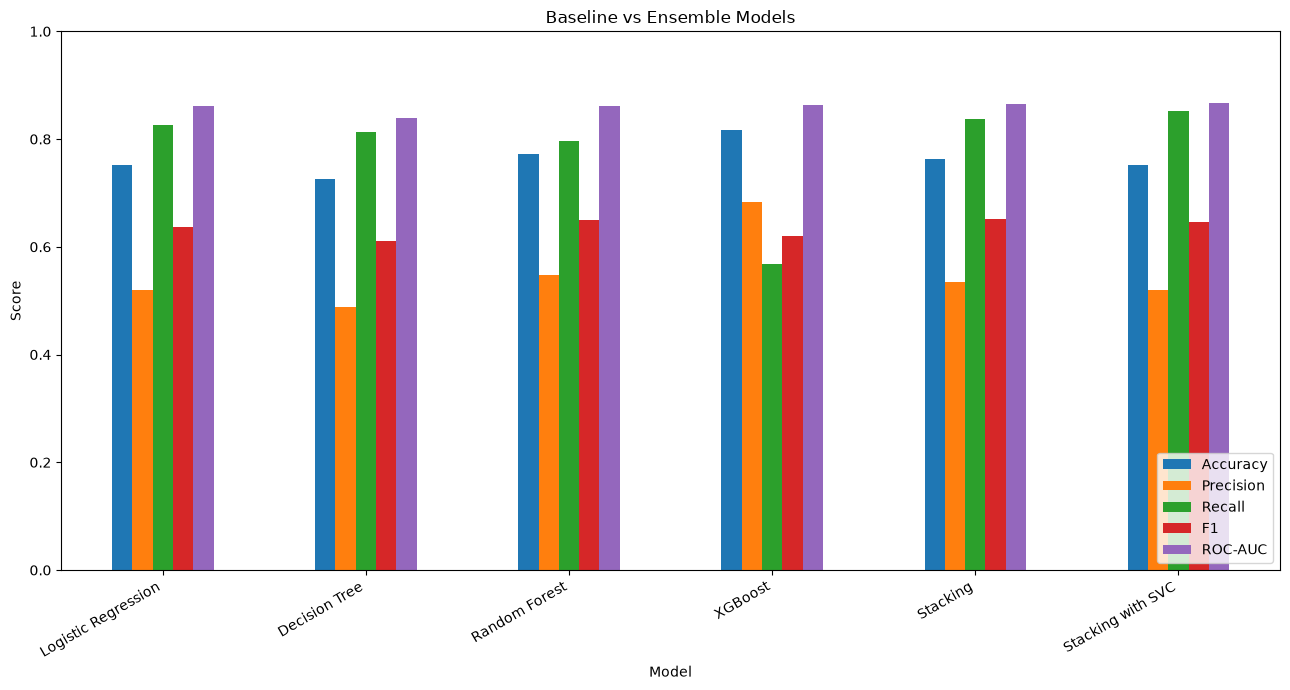

In [347]:
results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
].plot(
    kind="bar",
    figsize=(13,7),
    ylim=(0,1)
)

plt.title("Baseline vs Ensemble Models")
plt.ylabel("Score")
plt.xticks(rotation=30, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

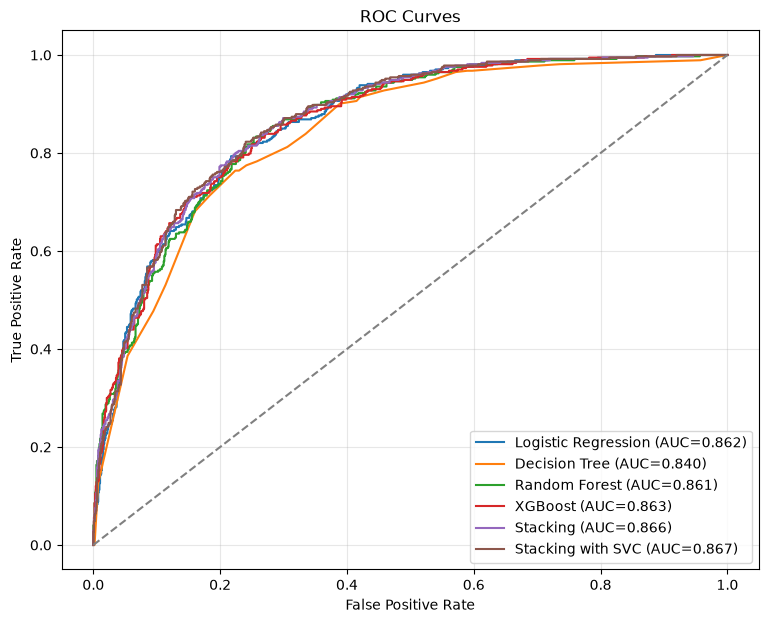

In [348]:
plt.figure(figsize=(9,7))

for name, y_prob in probabilities.items():

    fpr, tpr, thresholds = roc_curve(
        y_test,
        y_prob
    )

    auc = roc_auc_score(y_test, y_prob)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC={auc:.3f})"
    )

plt.plot(
    [0,1],
    [0,1],
    "--",
    color="gray"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Best Model: Stacking


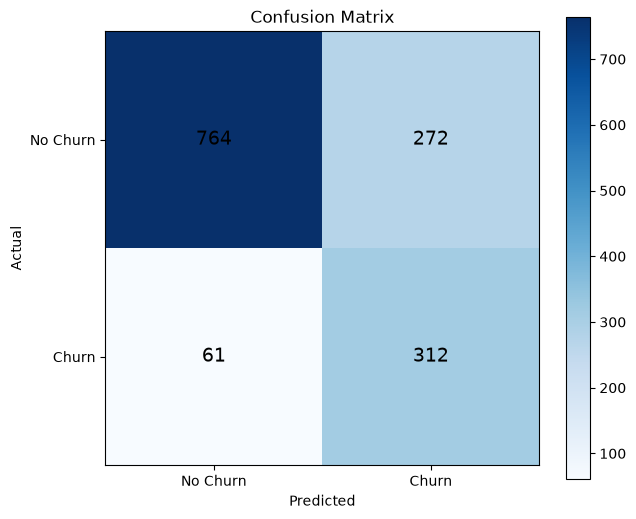

In [349]:
best_model_name = results_df.sort_values(
    by="F1",
    ascending=False
).iloc[0]["Model"]

best_model = models[best_model_name]

best_probabilities = probabilities[best_model_name]

best_predictions = predictions[best_model_name]

print("Best Model:", best_model_name)

cm = confusion_matrix(
    y_test,
    best_predictions
)

plt.figure(figsize=(7,6))

plt.imshow(cm, cmap="Blues")
plt.colorbar()

plt.xticks([0,1], ["No Churn", "Churn"])
plt.yticks([0,1], ["No Churn", "Churn"])

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

for i in range(2):
    for j in range(2):
        plt.text(
            j, i, cm[i,j],
            ha="center",
            va="center",
            fontsize=14
        )

plt.show()

In [350]:
threshold_results = []

for threshold in [0.5, 0.35]:

    y_threshold = (
        best_probabilities >= threshold
    ).astype(int)

    precision = precision_score(
        y_test,
        y_threshold,
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_threshold,
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_threshold,
        zero_division=0
    )

    accuracy = accuracy_score(
        y_test,
        y_threshold
    )

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "Accuracy": accuracy
    })

    print("\nThreshold:", threshold)
    print("Precision:", precision)
    print("Recall:", recall)
    print("F1:", f1)
    print("Accuracy:", accuracy)

    print(confusion_matrix(y_test, y_threshold))


threshold_df = pd.DataFrame(threshold_results)

display(threshold_df)

threshold_df.to_csv(
    f"{OUTPUT_DIR}/threshold_comparison.csv",
    index=False
)


Threshold: 0.5
Precision: 0.5342465753424658
Recall: 0.8364611260053619
F1: 0.6520376175548589
Accuracy: 0.7636621717530163
[[764 272]
 [ 61 312]]

Threshold: 0.35
Precision: 0.46853146853146854
Recall: 0.8981233243967829
F1: 0.6158088235294118
Accuracy: 0.7033356990773598
[[656 380]
 [ 38 335]]


,Threshold,Precision,Recall,F1,Accuracy
0,0.50,0.534247,0.836461,0.652038,0.763662
1,0.35,0.468531,0.898123,0.615809,0.703336


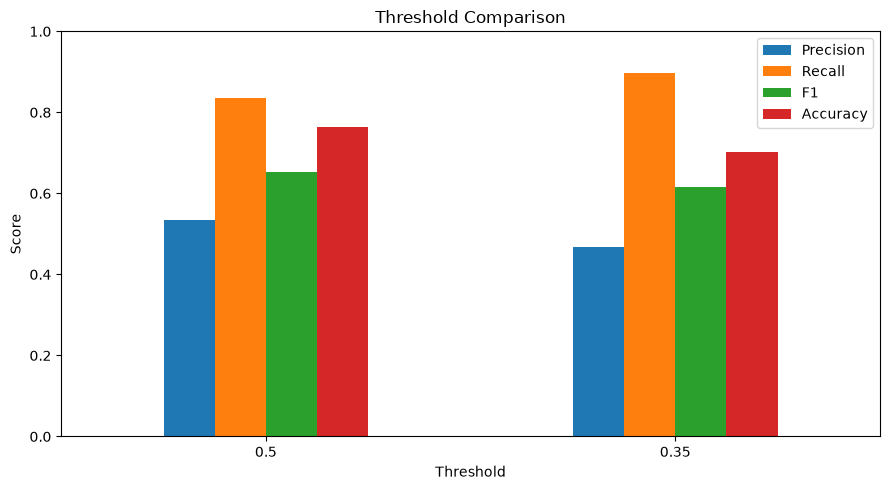

In [351]:
threshold_df.set_index("Threshold")[
    ["Precision", "Recall", "F1", "Accuracy"]
].plot(
    kind="bar",
    figsize=(9,5)
)

plt.title("Threshold Comparison")
plt.ylabel("Score")
plt.ylim(0,1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

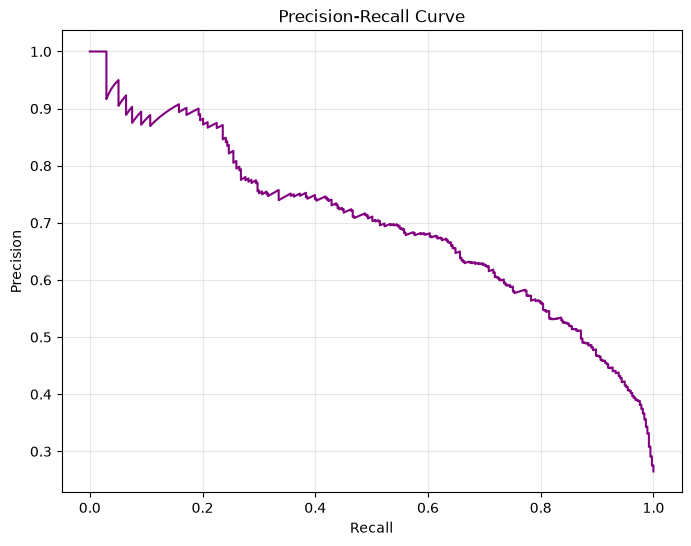

In [352]:
precision_values, recall_values, thresholds = (
    precision_recall_curve(
        y_test,
        best_probabilities
    )
)

plt.figure(figsize=(8,6))

plt.plot(
    recall_values,
    precision_values,
    color="purple"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.grid(alpha=0.3)
plt.show()

,Feature,Importance,Std
3,tenure,0.105828,0.008573
13,Contract,0.067439,0.017069
6,InternetService,0.050848,0.007678
0,SeniorCitizen,0.004009,0.002031
21,PaymentMethod_Electronic check,0.003981,0.001706
2,Dependents,0.003276,0.001700
16,TotalCharges,0.003147,0.004764
19,PaymentMethod_Bank transfer (automatic),0.003070,0.002377
8,OnlineBackup,0.002441,0.004446
1,Partner,0.002296,0.001972


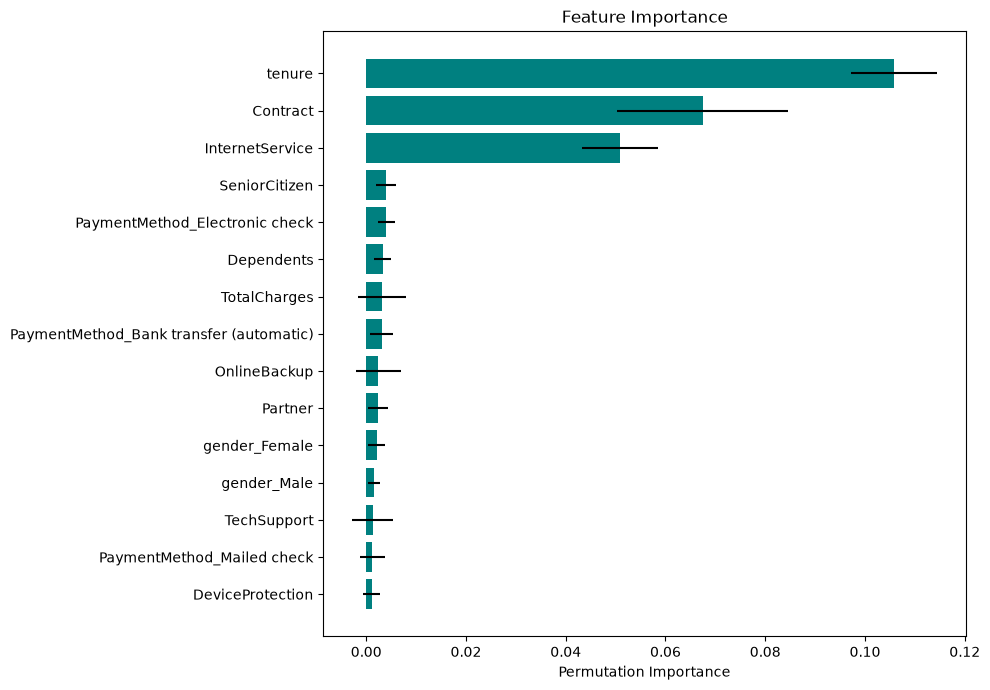

In [353]:
importance_result = permutation_importance(
    best_model,
    X_test,
    y_test,
    scoring="f1",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance_result.importances_mean,
    "Std": importance_result.importances_std
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

display(importance_df)

importance_df.to_csv(
    f"{OUTPUT_DIR}/feature_importance.csv",
    index=False
)

top_features = importance_df.head(15).sort_values(
    by="Importance"
)

plt.figure(figsize=(10,7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"],
    xerr=top_features["Std"],
    color="teal"
)

plt.title("Feature Importance")
plt.xlabel("Permutation Importance")
plt.tight_layout()
plt.show()

In [355]:
from sklearn.ensemble import GradientBoostingClassifier

X_train_final, X_val, y_train_final, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

depth_values = [2, 3, 4, 5]
estimator_values = [50, 100, 200, 300]
learning_rates = [0.01, 0.05, 0.1, 0.2]

tuning_results = []

for depth in depth_values:

    for n_estimators in estimator_values:

        for learning_rate in learning_rates:

            model = GradientBoostingClassifier(
                n_estimators=n_estimators,
                max_depth=depth,
                learning_rate=learning_rate,
                subsample=0.8,
                random_state=42
            )

            # Train model
            model.fit(X_train_final, y_train_final)

            # Predictions
            y_pred = model.predict(X_val)
            y_prob = model.predict_proba(X_val)[:, 1]

            # Evaluation
            tuning_results.append({
                "max_depth": depth,
                "n_estimators": n_estimators,
                "learning_rate": learning_rate,

                "Precision": precision_score(
                    y_val, y_pred, zero_division=0
                ),

                "Recall": recall_score(
                    y_val, y_pred, zero_division=0
                ),

                "F1": f1_score(
                    y_val, y_pred, zero_division=0
                ),

                "ROC-AUC": roc_auc_score(
                    y_val, y_prob
                )
            })

# Results
tuning_df = pd.DataFrame(tuning_results)

display(
    tuning_df.sort_values(
        by="F1",
        ascending=False
    ).head(10)
)

# Save results
tuning_df.to_csv(
    "gradient_boosting_tuning_results.csv",
    index=False
)

print("Gradient Boosting tuning completed!")

,max_depth,n_estimators,learning_rate,Precision,Recall,F1,ROC-AUC
18,3,50,0.10,0.722467,0.548495,0.623574,0.853986
6,2,100,0.10,0.723214,0.541806,0.619503,0.856862
21,3,100,0.05,0.725225,0.538462,0.618042,0.856250
9,2,200,0.05,0.713656,0.541806,0.615970,0.855289
22,3,100,0.10,0.691667,0.555184,0.615955,0.849109
13,2,300,0.05,0.705628,0.545151,0.615094,0.852835
10,2,200,0.10,0.697872,0.548495,0.614232,0.852562
37,4,100,0.05,0.701299,0.541806,0.611321,0.852968
34,4,50,0.10,0.689076,0.548495,0.610801,0.849119
3,2,50,0.20,0.696970,0.538462,0.607547,0.852417


Gradient Boosting tuning completed!


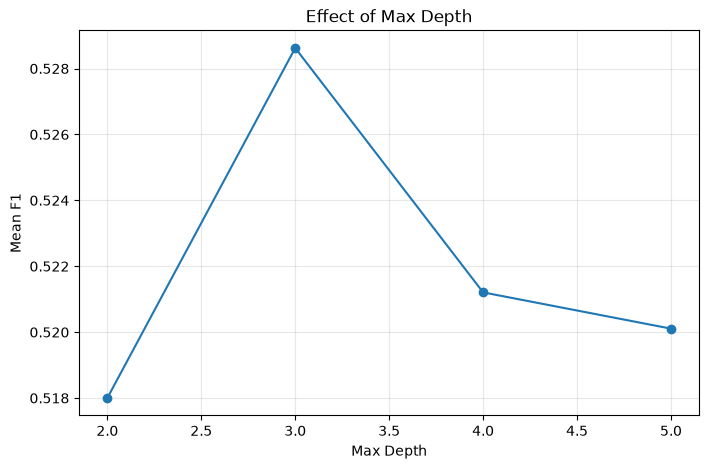

In [356]:
depth_curve = tuning_df.groupby(
    "max_depth"
)["F1"].mean()

plt.figure(figsize=(8,5))

plt.plot(
    depth_curve.index,
    depth_curve.values,
    marker="o"
)

plt.xlabel("Max Depth")
plt.ylabel("Mean F1")
plt.title("Effect of Max Depth")
plt.grid(alpha=0.3)
plt.show()

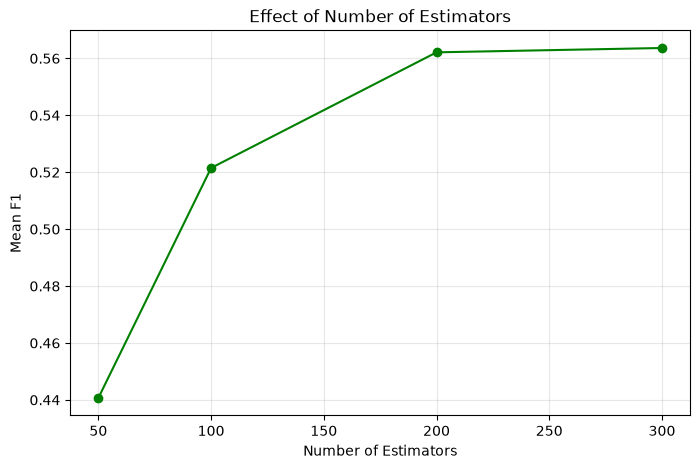

In [357]:
estimator_curve = tuning_df.groupby(
    "n_estimators"
)["F1"].mean()

plt.figure(figsize=(8,5))

plt.plot(
    estimator_curve.index,
    estimator_curve.values,
    marker="o",
    color="green"
)

plt.xlabel("Number of Estimators")
plt.ylabel("Mean F1")
plt.title("Effect of Number of Estimators")
plt.grid(alpha=0.3)
plt.show()

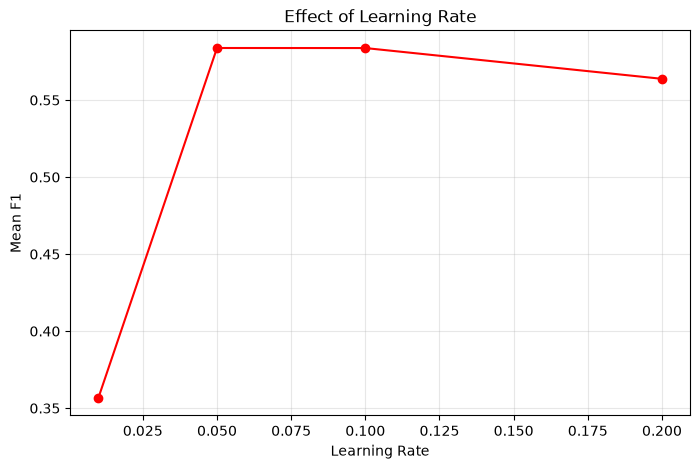

In [358]:
learning_curve = tuning_df.groupby(
    "learning_rate"
)["F1"].mean()

plt.figure(figsize=(8,5))

plt.plot(
    learning_curve.index,
    learning_curve.values,
    marker="o",
    color="red"
)

plt.xlabel("Learning Rate")
plt.ylabel("Mean F1")
plt.title("Effect of Learning Rate")
plt.grid(alpha=0.3)
plt.show()

In [359]:
business_threshold = 0.35

risk_predictions = (
    best_probabilities >= business_threshold
).astype(int)

customer_risk = X_test.copy()

customer_risk["Actual_Churn"] = y_test.values

customer_risk["Churn_Probability"] = best_probabilities

customer_risk["Predicted_Churn"] = risk_predictions

customer_risk["Risk_Level"] = np.where(
    customer_risk["Churn_Probability"] >= 0.70,
    "High",
    np.where(
        customer_risk["Churn_Probability"] >= 0.35,
        "Medium",
        "Low"
    )
)

customer_risk = customer_risk.sort_values(
    by="Churn_Probability",
    ascending=False
)

display(customer_risk.head(20))

customer_risk.to_csv(
    f"{OUTPUT_DIR}/customer_risk_scores.csv",
    index=False
)

,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,...,gender_Female,gender_Male,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,Actual_Churn,Churn_Probability,Predicted_Churn,Risk_Level
4800,1,0,0,-1.277445,1,1,2,-1,-1,-1,...,0,1,0,0,1,0,1,0.913608,1,High
2208,1,1,0,-1.277445,1,1,2,-1,-1,1,...,1,0,0,0,1,0,1,0.912576,1,High
2577,0,0,0,-1.277445,1,1,2,-1,-1,-1,...,1,0,0,0,1,0,1,0.911778,1,High
2191,1,0,0,-1.277445,1,-1,2,-1,-1,-1,...,1,0,0,0,1,0,1,0.908469,1,High
534,0,0,0,-1.277445,1,1,2,-1,-1,-1,...,1,0,0,0,1,0,1,0.908378,1,High
1600,1,0,0,-1.277445,1,1,2,-1,-1,1,...,0,1,0,0,1,0,1,0.908094,1,High
585,1,0,0,-1.277445,1,1,2,-1,-1,-1,...,1,0,0,0,1,0,1,0.907086,1,High
1410,1,0,0,-1.236724,1,1,2,-1,-1,-1,...,1,0,0,0,1,0,1,0.905544,1,High
1371,1,0,0,-1.277445,1,-1,2,-1,-1,-1,...,1,0,0,0,1,0,1,0.903363,1,High
642,0,0,0,-1.277445,1,-1,2,-1,-1,-1,...,0,1,0,0,1,0,1,0.901235,1,High


In [360]:
print("TELECOM CUSTOMER CHURN PROJECT")

print("\nBest Model:", best_model_name)

print("\nModel Comparison:")
display(results_df.sort_values(by="F1", ascending=False))

print("\nThreshold Comparison:")
display(threshold_df)

print("\nTop 10 Important Features:")
display(importance_df.head(10))

print("\nBest XGBoost Parameters:")
display(
    tuning_df.sort_values(
        by="F1",
        ascending=False
    ).head(1)
)

print("\nCustomer Risk Distribution:")
print(customer_risk["Risk_Level"].value_counts())

TELECOM CUSTOMER CHURN PROJECT

Best Model: Stacking

Model Comparison:


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
4,Stacking,0.763662,0.534247,0.836461,0.652038,0.865943
2,Random Forest,0.772179,0.547970,0.796247,0.649180,0.860774
5,Stacking with SVC,0.752307,0.519608,0.852547,0.645685,0.867068
0,Logistic Regression,0.751597,0.519393,0.825737,0.637681,0.862069
3,XGBoost,0.816182,0.683871,0.568365,0.620791,0.863143
1,Decision Tree,0.725337,0.488710,0.812332,0.610272,0.839968



Threshold Comparison:


,Threshold,Precision,Recall,F1,Accuracy
0,0.50,0.534247,0.836461,0.652038,0.763662
1,0.35,0.468531,0.898123,0.615809,0.703336



Top 10 Important Features:


,Feature,Importance,Std
3,tenure,0.105828,0.008573
13,Contract,0.067439,0.017069
6,InternetService,0.050848,0.007678
0,SeniorCitizen,0.004009,0.002031
21,PaymentMethod_Electronic check,0.003981,0.001706
2,Dependents,0.003276,0.001700
16,TotalCharges,0.003147,0.004764
19,PaymentMethod_Bank transfer (automatic),0.003070,0.002377
8,OnlineBackup,0.002441,0.004446
1,Partner,0.002296,0.001972



Best XGBoost Parameters:


,max_depth,n_estimators,learning_rate,Precision,Recall,F1,ROC-AUC
18,3,50,0.1,0.722467,0.548495,0.623574,0.853986



Customer Risk Distribution:
Risk_Level
Low       694
High      386
Medium    329
Name: count, dtype: int64

Project completed successfully!


# توصیه تجاری برای تیم حفظ مشتری (Customer Retention Team)
# موضوع: استفاده از مدل‌های یادگیری گروهی برای کاهش ریزش مشتریان شرکت مخابراتی

با توجه به نتایج حاصل از ارزیابی مدل‌های یادگیری ماشین، پیشنهاد می‌شود شرکت از مدل Stacking برای شناسایی مشتریان در معرض ریزش استفاده کند. این مدل با امتیاز F1 برابر با 0.652، Recall برابر با 83.65٪ و ROC-AUC برابر با 0.866 عملکرد مناسبی داشته است. همچنین نتایج نشان می‌دهد که مدل Random Forest با Accuracy برابر با 77.22٪ و Precision برابر با 54.80٪ نیز عملکرد قابل‌توجهی دارد. بنابراین انتخاب Stacking با توجه به اهمیت شناسایی حداکثری مشتریان در معرض ریزش، تصمیم مناسب‌تری برای هدف تجاری شرکت است.

بررسی اهمیت ویژگی‌ها نشان می‌دهد که مدت زمان عضویت مشتری (Tenure) با اهمیت 0.1058 مهم‌ترین عامل مرتبط با ریزش است. پس از آن نوع قرارداد (Contract) با اهمیت 0.0674 و نوع خدمات اینترنت (InternetService) با اهمیت 0.0508 قرار دارند. بنابراین پیشنهاد می‌شود شرکت برای مشتریان تازه‌وارد برنامه‌های وفاداری، تخفیف در ماه‌های ابتدایی عضویت و پشتیبانی ویژه در نظر بگیرد. همچنین ارائه پیشنهادهای جذاب برای تبدیل قراردادهای ماهانه به قراردادهای بلندمدت و بهبود کیفیت خدمات اینترنت می‌تواند به کاهش ریزش کمک کند.

در بررسی آستانه تصمیم‌گیری، کاهش آستانه از 0.5 به 0.35 باعث افزایش Recall از 83.65٪ به 89.81٪ شده است؛ اما Precision از 53.42٪ به 46.85٪ کاهش یافته است. این موضوع نشان می‌دهد که با آستانه 0.35 مشتریان بیشتری که واقعاً قصد ترک شرکت دارند شناسایی می‌شوند، ولی تعداد مشتریانی که به اشتباه پرخطر تشخیص داده می‌شوند نیز افزایش می‌یابد. بنابراین پیشنهاد می‌شود شرکت از آستانه 0.35 برای شناسایی گسترده‌تر مشتریان پرخطر استفاده کند، اما برای ارائه تخفیف‌های پرهزینه، بررسی تکمیلی انجام دهد.

در نهایت، پیشنهاد می‌شود شرکت ابتدا این سیستم را به‌صورت آزمایشی اجرا کرده و میزان کاهش ریزش، هزینه تماس‌ها و تخفیف‌ها و افزایش وفاداری مشتریان را بررسی کند. این رویکرد به شرکت کمک می‌کند منابع خود را هدفمندتر مصرف کند، مشتریان ارزشمند را حفظ نماید و از هزینه‌های جذب مشتریان جدید بکاهد.